## ABMIL Model Development

## Importing and loading data

In [ ]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FEAT = ROOT / "features/lunit_vits16"

manifest = pd.read_csv(ROOT / "data/manifest.csv", dtype={"patient_id": str})
# first patient from yale cohort
row = manifest[manifest.cohort == "yale"].iloc[0]

with h5py.File(FEAT / "yale" / f"{row.patient_id}.h5") as f:
    # stored as fp16; models expect fp32
    feats = f["features"][:].astype(np.float32)  

x = torch.from_numpy(feats)          

## Developing the model

In [ ]:
class ABMIL(nn.Module):
    def __init__(self, in_dim=384, hidden_dim=128, attn_dim=64, dropout=0.25):
        super().__init__()
        # projection layer to reduce embedding dimension from 384 to 128
        self.proj_layer = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), #(384, 128)
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.attn_branch_u = nn.Sequential(
            nn.Linear(hidden_dim, attn_dim),
            nn.Sigmoid()
        )
        self.attn_branch_v = nn.Sequential(
            nn.Linear(hidden_dim, attn_dim),
            nn.Tanh()
        )
        self.attn_w = nn.Linear(attn_dim, 1)
        self.linear_head = nn.Linear(hidden_dim, 1)
        
    def forward(self, X):
        h = self.proj_layer(X)
        sig_side = self.attn_branch_u(h)
        tan_side = self.attn_branch_v(h)
        a_scores = self.attn_w(sig_side * tan_side)
        a = F.softmax(a_scores, dim=0)
        # slide/patient embedding
        z = torch.sum(a * h, dim=0)
        logits = self.linear_head(z)
        return logits, a

In [ ]:
# Functions to track dimensions and tensor stats during the forward pass
def describe(name, t):
    print(f"{name:8s} shape={tuple(t.shape)}  min={t.min():.3f}  max={t.max():.3f}  "
          f"mean={t.mean():.3f}  zeros={(t == 0).float().mean():.1%}")
    
def trace(model, x):
    """Print the output of each top-level layer as the real forward pass runs."""
    handles = [m.register_forward_hook(lambda mod, inp, out, name=name: describe(name, out))
               for name, m in model.named_children()]
    try:
        logit, a = model(x)
    finally:
        for h in handles:
            h.remove()                      
    describe("attn weights", a)
    print("sum of weights:", a.sum().item())
    return logit, a

In [ ]:
# Note: the attention weights are only printed after the forward pass - why they are out of order
trace(ABMIL(), x)

proj_layer shape=(1920, 128)  min=0.000  max=6.290  mean=0.466  zeros=66.2%
attn_branch_u shape=(1920, 64)  min=0.062  max=0.912  mean=0.516  zeros=0.0%
attn_branch_v shape=(1920, 64)  min=-0.990  max=0.984  mean=-0.037  zeros=0.0%
attn_w   shape=(1920, 1)  min=-0.168  max=0.436  mean=0.121  zeros=0.0%
linear_head shape=(1,)  min=-0.625  max=-0.625  mean=-0.625  zeros=0.0%
attn weights shape=(1920, 1)  min=0.000  max=0.001  mean=0.001  zeros=0.0%
sum of weights: 1.000000238418579


(tensor([-0.6247], grad_fn=<UnsafeViewBackward0>),
 tensor([[0.0005],
         [0.0007],
         [0.0005],
         ...,
         [0.0004],
         [0.0005],
         [0.0005]], grad_fn=<SoftmaxBackward0>))

In [ ]:
# Total model parameters
model = ABMIL()
print(f"Total model parameters: {sum(p.numel() for p in model.parameters())}")

Total model parameters: 65986


All parameters in the model come from the linear FC layers:
- one in the projection layer (384 -> 128)
- two in the gated attention pooling layer (both 128 -> 64)
- one in the classifier head (128 -> 1)

In [ ]:
# In eval mode, model should return exactly the same logits -> deterministic
# In training mode, logits should vary slightly since dropout will zero random set of values
model.eval()
l1, _ = model(x); l2, _ = model(x)

print(f"Eval mode: {l1.item(), l2.item()}")
model.train()
l3, _ = model(x); l4, _ = model(x)
print(f"Training mode: {l3.item(), l4.item()}")  

Eval mode: (0.5533692240715027, 0.5533692240715027)
Training mode: (0.5475857257843018, 0.5494195222854614)


In [ ]:
# Ensuring dev ABMIL model hasn't drifted from final ABMIL model
from her2_pcr_pathology_fm.models import ABMIL as ABMILFinal

dev, final = ABMIL(), ABMILFinal()
final.load_state_dict(dev.state_dict())
dev.eval(); final.eval()
print(torch.allclose(dev(x)[0], final(x)[0]))

True


## Training Loop

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from torch.nn import BCEWithLogitsLoss
from her2_pcr_pathology_fm.evaluate import load_bags

In [ ]:
# Loading tile bags
ids, y, bags = load_bags(cohort="yale", encoder="lunit_vits16", data_root=ROOT / "data", feat_root=ROOT / "features")
# Splitting bags into training and validation set
train_bags, val_bags, train_y, val_y, train_ids, val_ids = train_test_split(
    bags, y, ids, test_size=0.25, stratify=y, random_state=1337)

In [ ]:
@torch.no_grad()
def evaluate_abmil(model, bags, labels, criterion, device):
    model.eval()
    losses, probs = [], []
    for bag, label in zip(bags, labels):
        bag_t = torch.from_numpy(bag).to(device)
        label_t = torch.tensor([float(label)], device=device)
        logit, _ = model(bag_t)
        loss = criterion(logit, label_t).item()
        losses.append(loss)
        prob = torch.sigmoid(logit).item()  
        probs.append(prob)
    mean_loss = np.mean(losses)
    auc = roc_auc_score(labels, probs)
    return mean_loss, auc, probs

In [ ]:
def train_abmil(train_bags, train_y, val_bags=None, val_y=None, seed=1337,
                n_epochs=50, lr=1e-4, weight_decay=0.01, dropout=0.25, device="cpu"):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = ABMIL(dropout=dropout).to(device)
    n_pos = int(train_y.sum())
    n_neg = len(train_y) - n_pos
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = []
    for epoch in range(n_epochs):
        model.train()
        for i in rng.permutation(len(train_bags)):
            bag, label = train_bags[i], train_y[i]
            # Convert bags, labels to tensors
            bag_t = torch.from_numpy(bag).to(device)
            label_t = torch.tensor([float(label)], device=device)
            
            # forward pass
            logit, _ = model(bag_t)
            # calculate loss
            loss = criterion(logit, label_t)
            
            # backward pass
            # clearing gradients from previous step
            optimizer.zero_grad(set_to_none=True)
            # calculate gradients for all params
            loss.backward()
            # use gradients to update parameters to minimize loss
            optimizer.step()
        
        # Evaluate at the end of each epoch    
        row = {"epoch": epoch}
        row["mean_train_loss"], row["train_auc"], _ = evaluate_abmil(model, train_bags, train_y, criterion, device)
        if val_bags is not None:
            row["mean_val_loss"], row["val_auc"], _ = evaluate_abmil(model, val_bags, val_y, criterion, device)
        history.append(row)
    return model, history

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history, panels, log_panels=(), title=None):
    """panels: list of lists of history keys, one inner list per subplot.
       log_panels: indices of panels to draw with a log y-axis."""
    hist = pd.DataFrame(history)
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.5), squeeze=False)
    for j, (ax, keys) in enumerate(zip(axes.flat, panels)):
        for k in keys:
            ax.plot(hist["epoch"], hist[k], label=k)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
        if j in log_panels:
            ax.set_yscale("log")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### Step 1: Loss and Activations at Initialization

In [ ]:
# Setup
seed = 1337
torch.manual_seed(seed)
device="cpu"

model = ABMIL()
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.01)

n_pos = int(train_y.sum())
n_neg = len(train_y) - n_pos
criterion = BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg/n_pos], device=device))

In [ ]:
# Loss at initialization
mean_train_loss, train_auc, _ = evaluate_abmil(model, train_bags, train_y, criterion, device)
print(f"Mean training loss at initialization: {mean_train_loss}")

Mean training loss at initialization: 0.8051966769354684


Untrained model has probabilities close to 0.5 for each class -> binary cross entropy: ln(2) = 0.69
- pos_weight in criterion shifts it slightly to account for class imbalance

In [ ]:
# Checking activations at initialization
model.eval()
tanh_sat, sig_sat, dead = [], [], []

with torch.no_grad():
    for bag in train_bags[:10]:
        bag_t = torch.from_numpy(bag).to(device)
        h = model.proj_layer(bag_t)
        # tanh branch
        t = model.attn_branch_v(h)
        # sigmoid branch
        s = model.attn_branch_u(h)
        
        tanh_sat.append((t.abs() > 0.97).float().mean().item())
        sig_sat.append(((s < 0.03) | (s > 0.97)).float().mean().item())
        dead.append((h == 0).all(dim=0).float().mean().item())

print(f"tanh saturated (|x| > 0.97):        mean {np.mean(tanh_sat):.1%}, max {np.max(tanh_sat):.1%}")
print(f"sigmoid saturated (<0.03 or >0.97): mean {np.mean(sig_sat):.1%}, max {np.max(sig_sat):.1%}")
print(f"dead ReLU units (0 for every tile): mean {np.mean(dead):.1%}, max {np.max(dead):.1%}")        

tanh saturated (|x| > 0.97):        mean 0.0%, max 0.1%
sigmoid saturated (<0.03 or >0.97): mean 0.0%, max 0.0%
dead ReLU units (0 for every tile): mean 1.8%, max 3.9%


Checking that gradients can flow back through every layer by checking the following:
- tanh and sigmoid activations are not saturated near extremes
- few ReLU units are dead (zero for every tile)

### Step 2: Checking if model can learn - overfitting a few examples

In [ ]:
# First 4 bags of each label
idx = np.concatenate([np.where(train_y == 1)[0][:4], np.where(train_y == 0)[0][:4]])
tiny_bags = [train_bags[i] for i in idx]
tiny_y = train_y[idx]

In [ ]:
ovefit_test_model, overfit_test_history = train_abmil(tiny_bags, tiny_y, dropout=0, n_epochs=100)

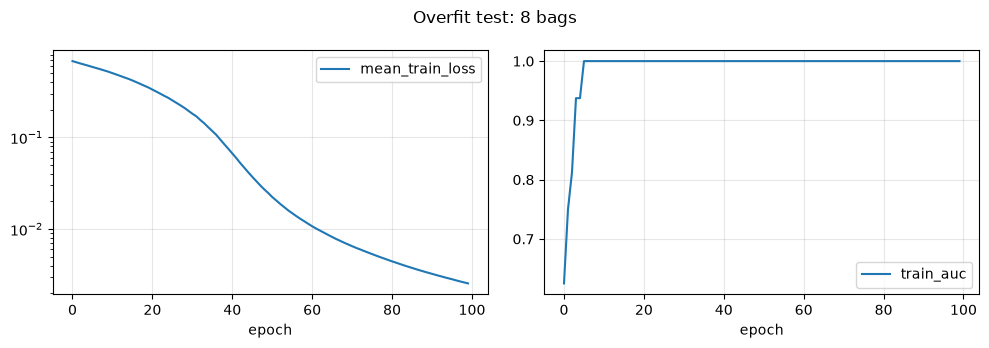

In [ ]:
plot_history(overfit_test_history, panels=[["mean_train_loss"], ["train_auc"]], log_panels=(0,),
             title="Overfit test: 8 bags")

As expected, training loss steadily decreases and train auc quickly reaches 1.

### Step 3: Full training loop

In [ ]:
model, history = train_abmil(train_bags, train_y, val_bags, val_y, n_epochs=50, lr=1e-4)

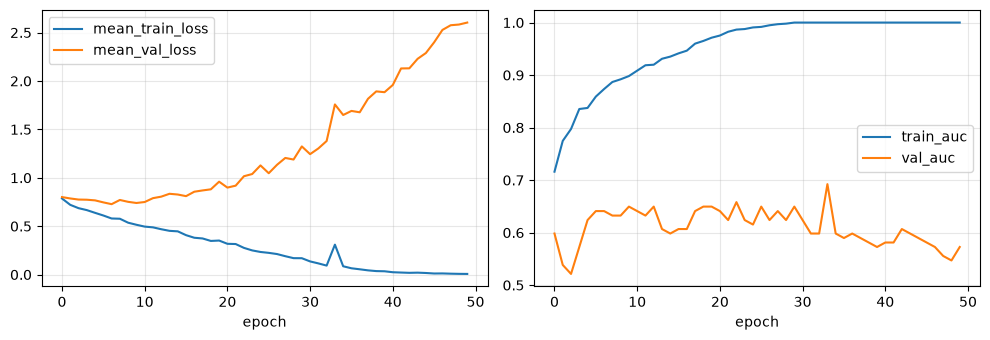

In [ ]:
plot_history(history, panels=[["mean_train_loss", "mean_val_loss"], ["train_auc", "val_auc"]])

- mean validation loss is relatively flat until 20 epochs and then rises rapidly
- validation auc peaks quickly and stays at the same rough level until falling after 30 epochs; this roughly matches the mean pool baseline auc
- auc is very noisy with only 21 patients (25% of data)

#### Step 4: Robustness of validation results - selecting epoch count

In [ ]:
# Choose epoch count from overlayed validation plots
runs = []
for split in [0, 1, 2]:
    # different stratified split for each run
    tr_b, va_b, tr_y, va_y = train_test_split(
        bags, y, test_size=0.25, stratify=y, random_state=split)

    # train with a matching seed (weights, dropout, shuffle order)
    _, history = train_abmil(tr_b, tr_y, va_b, va_y, seed=split, lr=1e-4, device=device)

    # 3. collect the history, labelled by run
    h = pd.DataFrame(history)
    h["run"] = split
    runs.append(h)
    
pilots = pd.concat(runs, ignore_index=True)

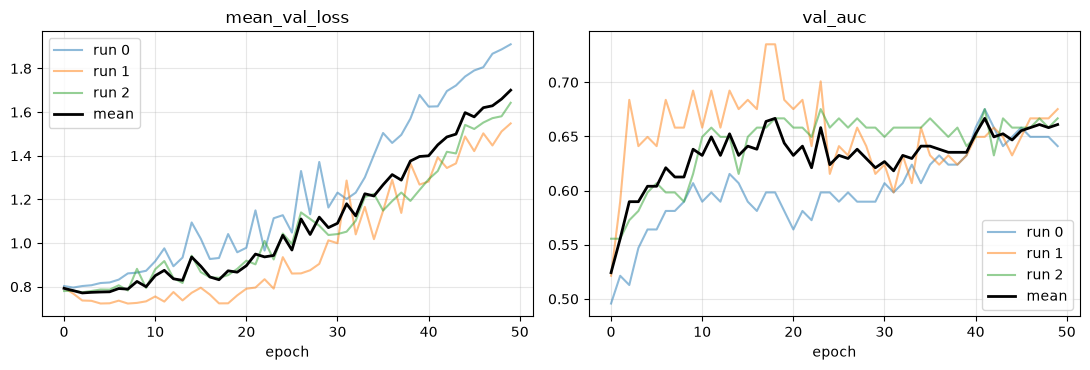

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for metric, ax in zip(["mean_val_loss", "val_auc"], axes):
    for split, g in pilots.groupby("run"):
        ax.plot(g.epoch, g[metric], alpha=0.5, label=f"run {split}")
    pilots.groupby("epoch")[metric].mean().plot(ax=ax, color="black", lw=2, label="mean")
    ax.set_title(metric); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
plt.show()

The average val_auc across the different splits has reached its max (~0.65) by epoch 20 so n_epochs will be set to 20. At this point the mean_val_loss has only increased by 0.1.

### Step 5: Selecting a learning rate

In [ ]:
lrs = [3e-4, 1e-4, 3e-5, 1e-5]
tr_b, va_b, tr_y, va_y = train_test_split(bags, y, test_size=0.25, stratify=y, random_state=0)

runs = []
for lr in lrs:
    _, history = train_abmil(tr_b, tr_y, va_b, va_y, lr=lr, seed=0, device=device)
    h = pd.DataFrame(history)
    h["lr"] = lr
    runs.append(h)
    best = h.loc[h.val_auc.idxmax()]
    print(f"lr {lr:.0e}: best val AUC {best.val_auc:.3f} at epoch {int(best.epoch)}, "
          f"final train loss {h.mean_train_loss.iloc[-1]:.3f}")
lr_runs = pd.concat(runs, ignore_index=True)

lr 3e-04: best val AUC 0.692 at epoch 20, final train loss 0.001
lr 1e-04: best val AUC 0.675 at epoch 41, final train loss 0.004
lr 3e-05: best val AUC 0.607 at epoch 38, final train loss 0.321
lr 1e-05: best val AUC 0.564 at epoch 49, final train loss 0.532


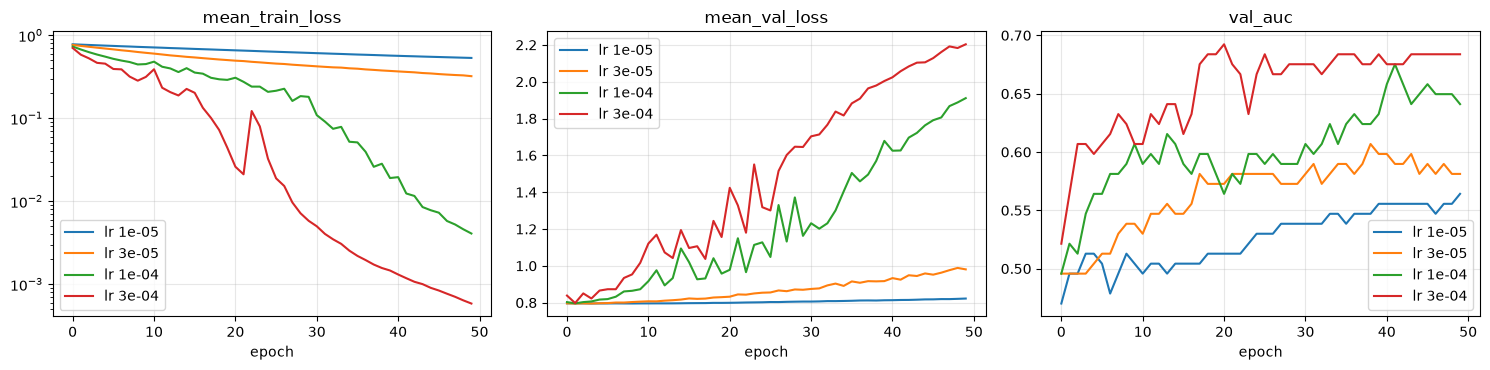

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for metric, ax in zip(["mean_train_loss", "mean_val_loss", "val_auc"], axes):
    for lr, g in lr_runs.groupby("lr"):
        ax.plot(g.epoch, g[metric], label=f"lr {lr:.0e}")
    ax.set_title(metric); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_yscale("log")                  # training loss spans a wide range
fig.tight_layout()
plt.show()

- can see the val_auc plot is inconsistent with the plot we have in step 4. This is due to the high variability caused by having such a small validation set
- the higher learning rate may reach slightly higher val_auc but this comes at the cost of a faster increasing mean_val_loss so a learning rate of 1e-4 will be kept


### Step 6: Checking activations after training

In [ ]:
model, _ = train_abmil(train_bags, train_y, n_epochs=20, lr=1e-4)

In [ ]:
# Checking activations after training
model.eval()
tanh_sat, sig_sat, dead = [], [], []

with torch.no_grad():
    for bag in train_bags[:10]:
        bag_t = torch.from_numpy(bag).to(device)
        h = model.proj_layer(bag_t)
        # tanh branch
        t = model.attn_branch_v(h)
        # sigmoid branch
        s = model.attn_branch_u(h)
        
        tanh_sat.append((t.abs() > 0.97).float().mean().item())
        sig_sat.append(((s < 0.03) | (s > 0.97)).float().mean().item())
        dead.append((h == 0).all(dim=0).float().mean().item())

print(f"tanh saturated (|x| > 0.97):        mean {np.mean(tanh_sat):.1%}, max {np.max(tanh_sat):.1%}")
print(f"sigmoid saturated (<0.03 or >0.97): mean {np.mean(sig_sat):.1%}, max {np.max(sig_sat):.1%}")
print(f"dead ReLU units (0 for every tile): mean {np.mean(dead):.1%}, max {np.max(dead):.1%}") 

tanh saturated (|x| > 0.97):        mean 7.3%, max 14.3%
sigmoid saturated (<0.03 or >0.97): mean 8.4%, max 14.1%
dead ReLU units (0 for every tile): mean 0.3%, max 1.6%


Still at reasonable levels
- less dead ReLU units than at initialization (2.0 -> 0.3%)
- 7-8% of tanh and sigmoid units saturated is normal given that they have learned and some have become more decisive/extreme

### Step 7. Attention spread

In [ ]:
model, _ = train_abmil(tr_b, tr_y, va_b, va_y, n_epochs=20, device=device)
model.eval()
rows = []
with torch.no_grad():
    for b in va_b:
        _, a = model(torch.from_numpy(b).to(device))
        a = a.squeeze()
        n = len(a)
        rows.append({"n_tiles": n,
                     "max_weight": a.max().item(),
                     "uniform_weight": 1 / n,
                     "norm_entropy": (-(a * a.log()).sum() / np.log(n)).item()})
pd.DataFrame(rows).describe()

,n_tiles,max_weight,uniform_weight,norm_entropy
count,22.000000,22.000000,22.000000,22.000000
mean,2408.090909,0.010583,0.000585,0.924815
std,1372.622027,0.009599,0.000384,0.041126
min,650.000000,0.001802,0.000172,0.827592
25%,1521.750000,0.005353,0.000299,0.905293
50%,2025.500000,0.008414,0.000494,0.932360
75%,3343.250000,0.011690,0.000658,0.953246
max,5825.000000,0.047603,0.001538,0.984925


- mean normalized entropy of 0.92 means attention is spread out but not uniform; the model uses information from many tiles while still weighting some more than others
- the most important tile (max_weight) is about 17x larger than if the tiles had uniform weight showing that some tiles are weighted more highly
- since the model is not relying on only a small subset of tiles, it is a moderately re-weighted mean which explains why the val_auc is similar to that of the mean pooling baseline

#### Ensuring function versions in models.py and dev notebook haven't drifted apart

In [ ]:
from her2_pcr_pathology_fm.models import train_abmil as train_abmil_final

settings = dict(seed=0, n_epochs=3, lr=1e-4, weight_decay=0.01, dropout=0.25, device=device)

_, h_dev   = train_abmil(tr_b, tr_y, va_b, va_y, **settings)        # notebook version
_, h_final = train_abmil_final(tr_b, tr_y, va_b, va_y, **settings)  # models.py version

dev, final = pd.DataFrame(h_dev), pd.DataFrame(h_final)
print(dev.columns.tolist())
print(final.columns.tolist())
print("same values:", np.allclose(dev.values, final.values))

['epoch', 'mean_train_loss', 'train_auc', 'mean_val_loss', 'val_auc']
['epoch', 'mean_train_loss', 'train_auc', 'mean_val_loss', 'val_auc']
same values: True


In [ ]:
from her2_pcr_pathology_fm.models import abmil_fit_predict

probs = abmil_fit_predict(tr_b, tr_y, va_b, seed=0)
print(probs.shape, probs[:5])
print("val AUC:", roc_auc_score(va_y, probs))

(22,) [0.36461967 0.98680508 0.79942858 0.00777744 0.59406281]
val AUC: 0.5811965811965811
